# ✈️ Airline Data Platform — EDA & Data Understanding (Giai Đoạn 1)

> **Mục tiêu notebook:**  
> Áp dụng framework Senior Data Analyst để đọc hiểu toàn diện cấu trúc, chất lượng  
> và các vấn đề tiềm ẩn trong dữ liệu thô **trước khi** tiến hành bất kỳ transformation nào.

**Nguyên tắc bắt buộc (xuyên suốt notebook):**
- ❌ Không sửa, ghi đè hoặc xoá raw data trực tiếp.
- ❌ Không tự kết luận business khi rule chưa được owner/PM xác nhận.
- ✅ Phân biệt rõ: `NULL` / blank / `0` / dash `-` / sentinel `-9999`.
- ✅ Mọi finding phải ghi rõ số dòng bị ảnh hưởng.
- 📊 Biểu đồ chỉ được tạo khi giúp phát hiện **distribution, outlier, missing-data pattern hoặc biến động theo thời gian** rõ hơn bảng số; mỗi biểu đồ phải nêu rõ **mục tiêu kiểm tra** và **không được dùng để kết luận business** khi rule chưa xác nhận.

---
**Cấu trúc notebook:**  
`0. Setup` → `1. Data Inventory` → `2. Data Understanding` → `3. Data Profiling`  
→ `4. Data-Quality Issues` → `5. Business-Rule Questions` → `6. Profiling Charts` → `7. Cleaning Plan` → `8. Executive Summary`


---
## 0 · Setup — Working Directory & Libraries


In [1]:
import os
from pathlib import Path

# Notebook nằm trong <project_root>/notebooks/
# → cần lên 1 cấp để dùng data/raw/... từ project root
notebook_dir = Path(os.getcwd())
PROJECT_ROOT = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
os.chdir(PROJECT_ROOT)

OUTPUT_IMG_DIR = Path("output/image")
OUTPUT_IMG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Working directory : {Path.cwd()}')
print(f'data/raw/ exists  : {(Path.cwd() / "data/raw").exists()}')
print(f'output/image/ dir : {Path("output/image").exists()}')


Working directory : c:\airline-data-platform
data/raw/ exists  : True


In [2]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.2f}'.format)

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'font.size': 9,
})

# DuckDB in-memory — chỉ đọc CSV, không tạo file database
con = duckdb.connect()

for tbl, path in [
    ('raw_flights',  'data/raw/flights.csv'),
    ('raw_airports', 'data/raw/airports.csv'),
    ('raw_carriers', 'data/raw/carriers.csv'),
    ('raw_weather',  'data/raw/weather.csv'),
]:
    con.execute(f"CREATE OR REPLACE VIEW {tbl} AS SELECT * FROM read_csv_auto('{path}')")

print('DuckDB views ready: raw_flights, raw_airports, raw_carriers, raw_weather')


DuckDB views ready: raw_flights, raw_airports, raw_carriers, raw_weather


---
## 1 · Data Inventory

**Mục tiêu:** Liệt kê file, số dòng, số cột, kích thước, nguồn dữ liệu, phạm vi thời gian và tần suất cập nhật.


In [3]:
# 1.1 Row count, column count, file size
inventory = []
for tbl, fname, source in [
    ('raw_flights',  'data/raw/flights.csv',  'Synthetic (mô phỏng US DOT BTS)'),
    ('raw_airports', 'data/raw/airports.csv', 'Reference table'),
    ('raw_carriers', 'data/raw/carriers.csv', 'Reference table'),
    ('raw_weather',  'data/raw/weather.csv',  'Synthetic weather per airport/day'),
]:
    rows = con.execute(f'SELECT COUNT(*) FROM {tbl}').fetchone()[0]
    cols = con.execute(f'DESCRIBE {tbl}').df().shape[0]
    fsize = os.path.getsize(fname)
    inventory.append({
        'File': fname,
        'Rows': f'{rows:,}',
        'Columns': cols,
        'Size': f'{fsize/1024:.1f} KB',
        'Source': source,
        'Update Freq': 'Batch / static',
    })

inv_df = pd.DataFrame(inventory)
print('=== DATA INVENTORY ===')
print(inv_df.to_string(index=False))


=== DATA INVENTORY ===
                 File   Rows  Columns      Size                            Source    Update Freq
 data/raw/flights.csv 60,180       20 4480.8 KB   Synthetic (mô phỏng US DOT BTS) Batch / static
data/raw/airports.csv     40        8    2.4 KB                   Reference table Batch / static
data/raw/carriers.csv     10        5    0.4 KB                   Reference table Batch / static
 data/raw/weather.csv  3,640        8  150.6 KB Synthetic weather per airport/day Batch / static


In [4]:
# 1.2 Schema của từng bảng
for tbl in ['raw_flights', 'raw_airports', 'raw_carriers', 'raw_weather']:
    schema = con.execute(f'DESCRIBE {tbl}').df()[['column_name', 'column_type']]
    print(f'\n{"-"*50}')
    print(f'  {tbl.upper()}')
    print(f'{"-"*50}')
    print(schema.to_string(index=False))



--------------------------------------------------
  RAW_FLIGHTS
--------------------------------------------------
            column_name column_type
              flight_id      BIGINT
            flight_date        DATE
           carrier_code     VARCHAR
          flight_number      BIGINT
            tail_number     VARCHAR
                 origin     VARCHAR
                   dest     VARCHAR
scheduled_departure_min      BIGINT
         distance_miles      DOUBLE
 scheduled_air_time_min      BIGINT
          dep_delay_min      BIGINT
          arr_delay_min      BIGINT
              cancelled      BIGINT
      cancellation_code     VARCHAR
               diverted      BIGINT
      carrier_delay_min      BIGINT
      weather_delay_min      BIGINT
          nas_delay_min      BIGINT
     security_delay_min      BIGINT
late_aircraft_delay_min      BIGINT

--------------------------------------------------
  RAW_AIRPORTS
--------------------------------------------------
 column_n

In [5]:
# 1.3 Phạm vi thời gian
date_range = con.execute("""
    SELECT
        MIN(flight_date)::VARCHAR                   AS min_date,
        MAX(flight_date)::VARCHAR                   AS max_date,
        COUNT(DISTINCT flight_date)                 AS distinct_dates
    FROM raw_flights
""").df()

weather_range = con.execute("""
    SELECT
        MIN(weather_date)::VARCHAR                  AS min_date,
        MAX(weather_date)::VARCHAR                  AS max_date,
        COUNT(DISTINCT weather_date)                AS distinct_dates
    FROM raw_weather
""").df()

print('flights.csv  — date range:')
print(date_range.to_string(index=False))
print('\nweather.csv  — date range:')
print(weather_range.to_string(index=False))


flights.csv  — date range:
  min_date   max_date  distinct_dates
2024-01-01 2024-03-31              91

weather.csv  — date range:
  min_date   max_date  distinct_dates
2024-01-01 2024-03-31              91


---
## 2 · Data Understanding — Grain, Keys & Relationships

**Mục tiêu:** Xác định grain (một dòng đại diện cho cái gì?), loại bảng (Fact / Dimension),  
candidate key, kiểm tra uniqueness và xác định các cột có thể JOIN.

| Bảng | Grain | Loại bảng |
|---|---|---|
| `flights.csv` | 1 flight leg (chuyến bay cụ thể) theo ngày | **Fact table** |
| `airports.csv` | 1 sân bay | **Dimension table** |
| `carriers.csv` | 1 hãng hàng không | **Dimension table** |
| `weather.csv` | 1 ngày tại 1 sân bay | **Fact/Dim hybrid** |


In [6]:
# 2.1 Uniqueness / candidate key check
print('=== GRAIN & UNIQUENESS CHECK ===\n')

checks = [
    ('flights  — flight_id',
     'raw_flights', 'flight_id'),
    ('flights  — natural key (carrier+number+date+origin)',
     'raw_flights', "carrier_code || CAST(flight_number AS VARCHAR) || CAST(flight_date AS VARCHAR) || origin"),
    ('airports — airport_code',
     'raw_airports', 'airport_code'),
    ('carriers — carrier_code',
     'raw_carriers', 'carrier_code'),
    ('weather  — (airport_code, weather_date)',
     'raw_weather', "airport_code || CAST(weather_date AS VARCHAR)"),
]

results = []
for label, view, key in checks:
    total = con.execute(f'SELECT COUNT(*) FROM {view}').fetchone()[0]
    uniq  = con.execute(f'SELECT COUNT(DISTINCT {key}) FROM {view}').fetchone()[0]
    dups  = total - uniq
    status = 'UNIQUE' if dups == 0 else f'DUPLICATES: {dups:,}'
    results.append({'Key': label, 'Total': total, 'Unique': uniq, 'Duplicates': dups, 'Status': status})

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))


=== GRAIN & UNIQUENESS CHECK ===

                                                Key  Total  Unique  Duplicates          Status
                               flights  — flight_id  60180   60000         180 DUPLICATES: 180
flights  — natural key (carrier+number+date+origin)  60180   59992         188 DUPLICATES: 188
                            airports — airport_code     40      40           0          UNIQUE
                            carriers — carrier_code     10      10           0          UNIQUE
            weather  — (airport_code, weather_date)   3640    3640           0          UNIQUE


In [7]:
# 2.2 Referential integrity — kiểm tra Foreign Key violations
print('=== REFERENTIAL INTEGRITY (JOIN key validation) ===\n')

ri_checks = [
    ('flights.carrier_code -> carriers.carrier_code',
     'SELECT COUNT(*) FROM raw_flights WHERE carrier_code NOT IN (SELECT carrier_code FROM raw_carriers)'),
    ('flights.origin -> airports.airport_code',
     'SELECT COUNT(*) FROM raw_flights WHERE origin NOT IN (SELECT airport_code FROM raw_airports)'),
    ('flights.dest -> airports.airport_code',
     'SELECT COUNT(*) FROM raw_flights WHERE dest NOT IN (SELECT airport_code FROM raw_airports)'),
    ('weather.airport_code -> airports.airport_code',
     'SELECT COUNT(*) FROM raw_weather WHERE airport_code NOT IN (SELECT airport_code FROM raw_airports)'),
]

for label, sql in ri_checks:
    count = con.execute(sql).fetchone()[0]
    status = 'OK (0 orphans)' if count == 0 else f'ORPHAN ROWS: {count:,}'
    print(f'  [{status:22s}]  {label}')

# Chi tiet orphan dest
print('\nDetail — orphan dest codes:')
orphan = con.execute("""
    SELECT dest AS orphan_dest_code, COUNT(*) AS rows
    FROM raw_flights
    WHERE dest NOT IN (SELECT airport_code FROM raw_airports)
    GROUP BY dest ORDER BY rows DESC
""").df()
print(orphan.to_string(index=False) if not orphan.empty else '  (none)')


=== REFERENTIAL INTEGRITY (JOIN key validation) ===

  [OK (0 orphans)        ]  flights.carrier_code -> carriers.carrier_code
  [OK (0 orphans)        ]  flights.origin -> airports.airport_code
  [ORPHAN ROWS: 89       ]  flights.dest -> airports.airport_code
  [OK (0 orphans)        ]  weather.airport_code -> airports.airport_code

Detail — orphan dest codes:
orphan_dest_code  rows
             ZZZ    89


---
## 3 · Data Profiling

**Mục tiêu:** Kiểm tra missing/blank/sentinel, duplicate, format không thống nhất, distribution và outlier.  
Mọi giá trị bất thường được ghi là **"cần xác minh"** — không kết luận là lỗi.


In [8]:
# 3.1 Missing / blank / sentinel — flights.csv
print('=== MISSING / BLANK / SENTINEL — flights.csv ===\n')

prof = con.execute("""
    SELECT
        COUNT(*)                                                              AS total_rows,
        SUM(CASE WHEN TRIM(COALESCE(tail_number,'')) = ''  THEN 1 ELSE 0 END) AS tail_number_blank,
        SUM(CASE WHEN dep_delay_min = -9999               THEN 1 ELSE 0 END) AS dep_delay_sentinel_9999,
        SUM(CASE WHEN TRIM(COALESCE(cancellation_code,'')) = ''
                 THEN 1 ELSE 0 END)                                          AS cancel_code_blank_all,
        SUM(CASE WHEN cancelled = 1
                 AND TRIM(COALESCE(cancellation_code,'')) = ''
                 THEN 1 ELSE 0 END)                                          AS cancel_code_blank_on_cancelled,
        SUM(cancelled)                                                        AS cancelled_count,
        SUM(diverted)                                                         AS diverted_count
    FROM raw_flights
""").df()
print(prof.T.to_string(header=False))


=== MISSING / BLANK / SENTINEL — flights.csv ===

total_rows                     60,180.00
tail_number_blank                 337.00
dep_delay_sentinel_9999           116.00
cancel_code_blank_all          58,964.00
cancel_code_blank_on_cancelled      0.00
cancelled_count                 1,216.00
diverted_count                    125.00


In [9]:
# 3.2 Numeric stats — dep_delay_min & arr_delay_min
print('=== NUMERIC STATS — delay columns (sentinel -9999 excluded) ===\n')

stats = con.execute("""
    SELECT 'dep_delay_min' AS col,
        COUNT(*)                                                                        AS n,
        SUM(CASE WHEN dep_delay_min = -9999 THEN 1 ELSE 0 END)                         AS sentinel_9999,
        SUM(CASE WHEN dep_delay_min < 0 AND dep_delay_min != -9999 THEN 1 ELSE 0 END)  AS negative_count,
        MIN(CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)                   AS min_val,
        PERCENTILE_CONT(0.25) WITHIN GROUP
            (ORDER BY CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)         AS p25,
        PERCENTILE_CONT(0.50) WITHIN GROUP
            (ORDER BY CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)         AS median,
        ROUND(AVG(CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END), 2)         AS mean,
        PERCENTILE_CONT(0.75) WITHIN GROUP
            (ORDER BY CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)         AS p75,
        PERCENTILE_CONT(0.99) WITHIN GROUP
            (ORDER BY CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)         AS p99,
        MAX(CASE WHEN dep_delay_min != -9999 THEN dep_delay_min END)                   AS max_val
    FROM raw_flights
    UNION ALL
    SELECT 'arr_delay_min',
        COUNT(*), 0,
        SUM(CASE WHEN arr_delay_min < 0 THEN 1 ELSE 0 END),
        MIN(arr_delay_min),
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY arr_delay_min),
        PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY arr_delay_min),
        ROUND(AVG(arr_delay_min), 2),
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY arr_delay_min),
        PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY arr_delay_min),
        MAX(arr_delay_min)
    FROM raw_flights
""").df()
print(stats.to_string(index=False))


=== NUMERIC STATS — delay columns (sentinel -9999 excluded) ===

          col     n  sentinel_9999  negative_count  min_val   p25  median  mean   p75    p99  max_val
dep_delay_min 60180         116.00       14,131.00       -6  0.00    5.00 13.24 17.00 123.00      413
arr_delay_min 60180           0.00       26,768.00      -39 -7.00    1.00  7.36 12.00 116.00      411


In [10]:
# 3.3 Duplicate flight_id — chi tiet
print('=== DUPLICATE flight_id — CHI TIET ===\n')

dup_groups = con.execute("""
    SELECT COUNT(*) FROM (
        SELECT flight_id FROM raw_flights GROUP BY flight_id HAVING COUNT(*) > 1
    )
""").fetchone()[0]

extra_rows = con.execute("""
    SELECT SUM(cnt - 1) FROM (
        SELECT COUNT(*) AS cnt FROM raw_flights GROUP BY flight_id HAVING COUNT(*) > 1
    )
""").fetchone()[0]

print(f'Nhom flight_id bi duplicate: {dup_groups:,}')
print(f'So dong thua (extra rows)  : {extra_rows:,}')

print('\nTop 10 duplicate groups:')
top_dup = con.execute("""
    SELECT
        flight_id,
        COUNT(*)            AS dup_count,
        MIN(carrier_code)   AS carrier,
        MIN(CAST(flight_date AS VARCHAR)) AS min_date,
        MIN(origin)         AS origin,
        MIN(dest)           AS dest
    FROM raw_flights
    GROUP BY flight_id
    HAVING COUNT(*) > 1
    ORDER BY dup_count DESC, flight_id
    LIMIT 10
""").df()
print(top_dup.to_string(index=False))


=== DUPLICATE flight_id — CHI TIET ===

Nhom flight_id bi duplicate: 180
So dong thua (extra rows)  : 180

Top 10 duplicate groups:
 flight_id  dup_count carrier   min_date origin dest
       957          2      AA 2024-01-22    DAL  CLT
       976          2      AA 2024-02-09    MIA  EWR
      1579          2      F9 2024-03-29    MSY  DTW
      1819          2      AS 2024-03-11    MDW  BOS
      2418          2      DL 2024-03-21    EWR  LAX
      2930          2      AA 2024-02-12    JFK  ATL
      3265          2      WN 2024-02-20    BOS  CLE
      3326          2      DL 2024-01-24    PHX  AUS
      3505          2      UA 2024-01-09    SAN  IAH
      4106          2      AA 2024-03-31    ORD  MSP


In [11]:
# 3.4 Cancellation code distribution
print('=== CANCELLATION CODE DISTRIBUTION ===\n')

cancel_dist = con.execute("""
    SELECT
        COALESCE(cancellation_code, '[blank]') AS code,
        CASE COALESCE(cancellation_code, '')
            WHEN 'A' THEN 'Carrier'
            WHEN 'B' THEN 'Weather'
            WHEN 'C' THEN 'NAS'
            WHEN 'D' THEN 'Security'
            ELSE '(non-cancelled)'
        END                                    AS meaning,
        COUNT(*)                               AS rows,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM raw_flights
    GROUP BY cancellation_code
    ORDER BY rows DESC
""").df()
print(cancel_dist.to_string(index=False))

# Check: cancelled=1 nhung code blank -> anomaly
anomaly = con.execute("""
    SELECT COUNT(*) FROM raw_flights
    WHERE cancelled = 1 AND TRIM(COALESCE(cancellation_code,'')) = ''
""").fetchone()[0]
verdict = 'OK' if anomaly == 0 else f'CAN XAC MINH: {anomaly} rows'
print(f'\n[CHECK] cancelled=1 nhung cancellation_code blank: {anomaly} rows -> {verdict}')


=== CANCELLATION CODE DISTRIBUTION ===

   code         meaning  rows  pct_total
[blank] (non-cancelled) 58964      97.98
      A         Carrier   473       0.79
      B         Weather   373       0.62
      C             NAS   309       0.51
      D        Security    61       0.10

[CHECK] cancelled=1 nhung cancellation_code blank: 0 rows -> OK


In [12]:
# 3.5 Format check — trailing whitespace & short distance
print('=== FORMAT — airport_name trailing whitespace ===\n')

ws = con.execute("""
    SELECT airport_code, airport_name,
           LENGTH(airport_name) AS raw_len,
           LENGTH(TRIM(airport_name)) AS trimmed_len,
           LENGTH(airport_name) - LENGTH(TRIM(airport_name)) AS extra_spaces
    FROM raw_airports
    WHERE LENGTH(airport_name) != LENGTH(TRIM(airport_name))
""").df()
print(f'Airports co extra whitespace: {len(ws)}')
print(ws.to_string(index=False))

print('\n=== CAN XAC MINH — distance_miles < 50 miles ===\n')
short = con.execute("""
    SELECT origin, dest, distance_miles, COUNT(*) AS flights
    FROM raw_flights
    WHERE distance_miles < 50
    GROUP BY origin, dest, distance_miles
    ORDER BY distance_miles
""").df()
print(short.to_string(index=False) if not short.empty else '(none)')
if not short.empty:
    print('\n[CAN XAC MINH] Cac route tren co phai route hop le khong? (DQ-08)')


=== FORMAT — airport_name trailing whitespace ===

Airports co extra whitespace: 6
airport_code                      airport_name  raw_len  trimmed_len  extra_spaces
         ATL Hartsfield-Jackson Atlanta Intl         33           31             2
         EWR             Newark Liberty Intl         21           19             2
         PHX         Phoenix Sky Harbor Intl         25           23             2
         LGB              Long Beach Airport         20           18             2
         STL          St. Louis Lambert Intl         24           22             2
         OAK                    Oakland Intl         14           12             2

=== CAN XAC MINH — distance_miles < 50 miles ===

origin dest  distance_miles  flights
   JFK  LGA           10.60       56
   LGA  JFK           10.60       45
   OAK  SFO           10.80       29
   SFO  OAK           10.80       27
   DFW  DAL           11.50       47
   DAL  DFW           11.50       45
   ORD  MDW           15.2

---
## 4 · Data-Quality Issues

Bảng tổng hợp toàn bộ issues phát hiện được.  
**Mức độ:** 🔴 High · 🟡 Medium · 🟢 Low


In [13]:
# 4. Data-quality issues table — lay so lieu tu query thuc te
n_dup     = con.execute("SELECT SUM(cnt-1) FROM (SELECT COUNT(*) cnt FROM raw_flights GROUP BY flight_id HAVING COUNT(*)>1)").fetchone()[0]
n_sent    = con.execute("SELECT COUNT(*) FROM raw_flights WHERE dep_delay_min = -9999").fetchone()[0]
n_orphan  = con.execute("SELECT COUNT(*) FROM raw_flights WHERE dest NOT IN (SELECT airport_code FROM raw_airports)").fetchone()[0]
n_tail    = con.execute("SELECT COUNT(*) FROM raw_flights WHERE TRIM(COALESCE(tail_number,''))=''").fetchone()[0]
n_neg     = con.execute("SELECT COUNT(*) FROM raw_flights WHERE dep_delay_min < 0 AND dep_delay_min != -9999").fetchone()[0]
n_noncanc = con.execute("SELECT COUNT(*) FROM raw_flights WHERE cancelled = 0").fetchone()[0]
n_ws      = con.execute("SELECT COUNT(*) FROM raw_airports WHERE LENGTH(airport_name)!=LENGTH(TRIM(airport_name))").fetchone()[0]
n_short   = con.execute("SELECT COUNT(DISTINCT origin||dest) FROM raw_flights WHERE distance_miles < 50").fetchone()[0]

dq = [
    ('DQ-01','Duplicate flight_id','flights.flight_id',       f'{n_dup:,} extra rows', 'High',
     'flight_id sinh tu dong bi lap / nap 2 lan',   'Deduplicate ROW_NUMBER()',    'Co — giu ban nao?'),
    ('DQ-02','Sentinel -9999 dep_delay_min','flights.dep_delay_min', f'{n_sent:,}',  'Medium',
     'He thong nguon dung -9999 thay NULL',           'Replace NULL khi staging',    'Co — -9999=cancelled?'),
    ('DQ-03','Orphan dest code ZZZ','flights.dest',            f'{n_orphan:,}',       'Medium',
     'Ma san bay khong ton tai trong airports.csv',   'Filter hoac flag',            'Co — loai hay giu?'),
    ('DQ-04','Blank tail_number','flights.tail_number',        f'{n_tail:,}',         'Low',
     'Charter/ferry khong co tail number',            'Giu NULL',                    'Co — anh huong KPI?'),
    ('DQ-05','Negative dep_delay_min','flights.dep_delay_min', f'{n_neg:,}',          'Low',
     'Chuyen cat canh som hon ke hoach',              'Giu nguyen — co the hop le',  'Co — on-time threshold?'),
    ('DQ-06','cancel_code blank (non-cancelled)','flights',    f'{n_noncanc:,}',      'OK',
     'Blank = khong bi huy -> dung logic',            'Khong can xu ly',             'Khong'),
    ('DQ-07','Trailing whitespace airport_name','airports',    f'{n_ws:,}',           'Low',
     'Import thu cong khong trim',                    'TRIM() khi staging',          'Khong (ky thuat)'),
    ('DQ-08','distance_miles < 50 miles','flights.distance',   f'{n_short:,} routes', 'Can xac minh',
     'Chuyen ngan noi vung hoac loi data',            'Xac minh origin-dest',        'Co — route hop le?'),
]

dq_df = pd.DataFrame(dq, columns=[
    'ID','Issue','Col/Table','Rows','Level',
    'Cause (assumed)','Direction','Need owner?'
])
print('=== DATA-QUALITY ISSUES ===')
print(dq_df.to_string(index=False))


=== DATA-QUALITY ISSUES ===
   ID                             Issue             Col/Table           Rows        Level                             Cause (assumed)                  Direction             Need owner?
DQ-01               Duplicate flight_id     flights.flight_id 180 extra rows         High   flight_id sinh tu dong bi lap / nap 2 lan   Deduplicate ROW_NUMBER()       Co — giu ban nao?
DQ-02      Sentinel -9999 dep_delay_min flights.dep_delay_min            116       Medium         He thong nguon dung -9999 thay NULL   Replace NULL khi staging   Co — -9999=cancelled?
DQ-03              Orphan dest code ZZZ          flights.dest             89       Medium Ma san bay khong ton tai trong airports.csv           Filter hoac flag      Co — loai hay giu?
DQ-04                 Blank tail_number   flights.tail_number            337          Low          Charter/ferry khong co tail number                   Giu NULL     Co — anh huong KPI?
DQ-05            Negative dep_delay_min flights

---
## 5 · Business-Rule Questions — ĐÃ ĐƯỢC OWNER/PM PHÊ DUYỆT ✅

> **Trạng thái:** Toàn bộ 9 quyết định xử lý chất lượng dữ liệu (BQ-01 → BQ-09) và định hướng sử dụng **ELT (SQL/dbt)** đã được Owner/PM chính thức phê duyệt.

| Mã BQ | Mã DQ | Chủ đề | Quyết định đã chốt (Owner Approved) |
|---|---|---|---|
| **BQ-01** | DQ-01 | Duplicate `flight_id` | Giữ bản ghi nạp mới nhất `_loaded_at DESC` bằng `ROW_NUMBER()`; đối soát dòng thừa minh bạch. |
| **BQ-02** | DQ-02 | Sentinel `-9999` | Chuyển thành `NULL`, gán `delay_bucket = 'unknown'`; không làm méo `AVG()`, app hiển thị trạng thái đang cập nhật. |
| **BQ-03** | DQ-03 | Sân bay lạ `ZZZ` | Lọc khỏi bảng Fact chuẩn, cách ly vào bảng Quarantine để đội Data Governance trace ngược. |
| **BQ-04** | DQ-04 | Blank `tail_number` | Chuẩn hóa `NULL`, không dùng làm khóa JOIN; khách bay theo số hiệu chuyến, không gián đoạn dịch vụ. |
| **BQ-05 & 08** | DQ-05 | Delay âm & Chuẩn On-Time | Áp dụng chuẩn **US DOT A14 (`arr_delay_min < 15`)**; phân nhóm `early`, `on_time`, `minor`, `major`, `severe`. |
| **BQ-06** | DQ-08 | Chặng < 50 dặm | Giữ lại phục vụ Ops/nhiên liệu nhưng gắn cờ `repositioning` để app khách không bán vé nhầm. |
| **BQ-07** | — | Hủy chuyến (`Cancelled=1`) | Tách riêng Hủy và Trễ (`arr_delay_min = NULL`); phân loại mã hủy A-B-C-D bảo vệ quyền lợi bồi thường của khách và trách nhiệm của hãng. |
| **BQ-09** | — | Chuyển hướng (`Diverted`) | Tính là **ĐÃ BAY (Completion)** cho hãng, nhưng tính là **KHÔNG ĐÚNG GIỜ** cho khách để kích hoạt hỗ trợ mặt đất. |


In [14]:
# 5. Business-rule questions checklist
biz = [
    ('BQ-01','DQ-01','Duplicate flight_id',
     'Khi flight_id trung, giu ban nao? Ban moi nhat hay tat ca deu hop le?'),
    ('BQ-02','DQ-02','Sentinel -9999',
     'dep_delay_min=-9999 la (a) chuyen bi huy -> NULL, hay (b) sensor loi -> xu ly khac?'),
    ('BQ-03','DQ-03','Orphan dest ZZZ',
     'dest=ZZZ la loi data entry hay chuyen dac biet? Can loai khoi fact_flights khong?'),
    ('BQ-04','DQ-04','Blank tail_number',
     'Blank = khong co so duoi (ferry/charter) hay thieu data? Anh huong KPI nao?'),
    ('BQ-05','DQ-05','Negative dep_delay',
     'Delay am co tinh vao on-time khong? Nguong: delay <= 0 hay <= 15 min (US DOT standard)?'),
    ('BQ-06','DQ-08','distance < 50 miles',
     'Chuyen bay distance < 50 miles co phai route hop le? Co nguong minimum distance khong?'),
    ('BQ-07','—','Delay components khi cancelled',
     'Khi cancelled=1, carrier_delay_min... co gia tri khong? Tinh vao KPI delay tong khong?'),
    ('BQ-08','—','KPI On-Time definition',
     'Nguong on-time: dep_delay_min <= 15 (US DOT) hay <= 0? Ap dung ca arr_delay khong?'),
    ('BQ-09','—','Diverted flights',
     '125 chuyen diverted — tinh nhu cancelled hay nhu delay khi tinh ti le dung gio?'),
]

biz_df = pd.DataFrame(biz, columns=['ID','DQ-ref','Topic','Question'])
print('=== BUSINESS-RULE QUESTIONS (9 cau) ===\n')
for _, row in biz_df.iterrows():
    print(f'  [{row["ID"]}] (ref: {row["DQ-ref"]}) {row["Topic"]}')
    print(f'       -> {row["Question"]}')
    print()


=== BUSINESS-RULE QUESTIONS (9 cau) ===

  [BQ-01] (ref: DQ-01) Duplicate flight_id
       -> Khi flight_id trung, giu ban nao? Ban moi nhat hay tat ca deu hop le?

  [BQ-02] (ref: DQ-02) Sentinel -9999
       -> dep_delay_min=-9999 la (a) chuyen bi huy -> NULL, hay (b) sensor loi -> xu ly khac?

  [BQ-03] (ref: DQ-03) Orphan dest ZZZ
       -> dest=ZZZ la loi data entry hay chuyen dac biet? Can loai khoi fact_flights khong?

  [BQ-04] (ref: DQ-04) Blank tail_number
       -> Blank = khong co so duoi (ferry/charter) hay thieu data? Anh huong KPI nao?

  [BQ-05] (ref: DQ-05) Negative dep_delay
       -> Delay am co tinh vao on-time khong? Nguong: delay <= 0 hay <= 15 min (US DOT standard)?

  [BQ-06] (ref: DQ-08) distance < 50 miles
       -> Chuyen bay distance < 50 miles co phai route hop le? Co nguong minimum distance khong?

  [BQ-07] (ref: —) Delay components khi cancelled
       -> Khi cancelled=1, carrier_delay_min... co gia tri khong? Tinh vao KPI delay tong khong?

  [BQ-08] (r

---
## 6 · Biểu đồ Profiling

Chỉ tạo biểu đồ khi **chart > bảng số** về khả năng phát hiện vấn đề.  
Mỗi chart nêu rõ **mục tiêu kiểm tra** và không được dùng để kết luận business.

### 📊 Chart 1 — Distribution của `dep_delay_min`

**Mục tiêu kiểm tra:** Phân phối có right-skewed không? Vùng giá trị âm chiếm bao nhiêu? Outlier cực đại ở mức nào?  
> ⚠️ Biểu đồ này **không kết luận** delay âm là lỗi hay hợp lệ — cần BQ-05 xác nhận.


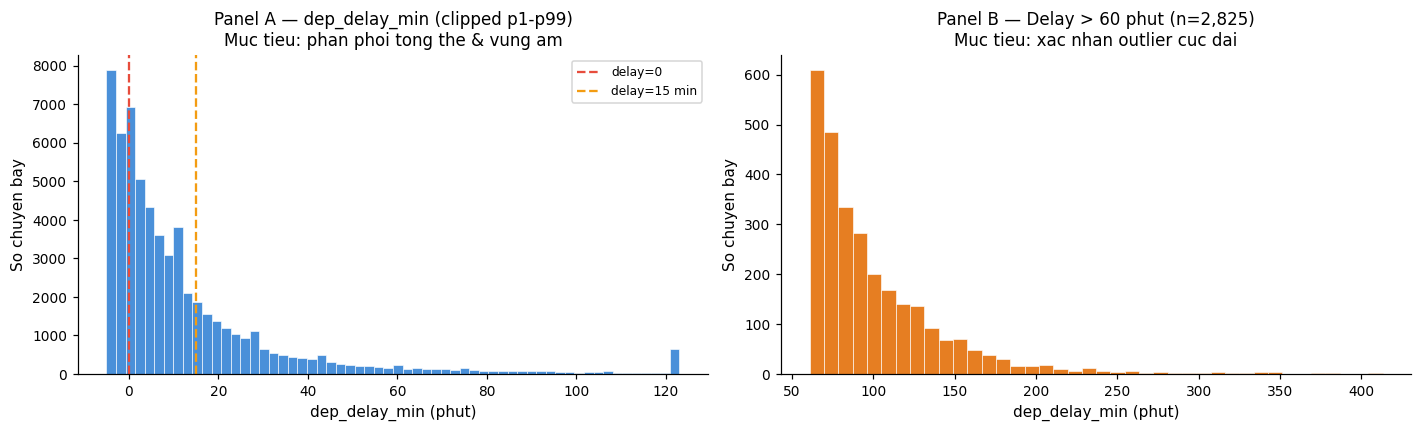

Negative delay (early departure): 14,131 rows (23.5%)
Delay > 60 min : 2,825 rows (4.7%)
Delay > 200 min: 89 rows — [CAN XAC MINH: outage hay loi data?]


In [15]:
# Chart 1: dep_delay_min distribution
delay_data = con.execute("""
    SELECT dep_delay_min FROM raw_flights WHERE dep_delay_min != -9999
""").df()['dep_delay_min']

p1, p99 = delay_data.quantile(0.01), delay_data.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Panel A: toan bo, clip p1-p99 tranh outlier lam truc meo
axes[0].hist(delay_data.clip(p1, p99), bins=60, color='#4A90D9', edgecolor='white', lw=0.4)
axes[0].axvline(0,  color='#E74C3C', lw=1.5, ls='--', label='delay=0')
axes[0].axvline(15, color='#F39C12', lw=1.5, ls='--', label='delay=15 min')
axes[0].set_title('Panel A — dep_delay_min (clipped p1-p99)\nMuc tieu: phan phoi tong the & vung am')
axes[0].set_xlabel('dep_delay_min (phut)')
axes[0].set_ylabel('So chuyen bay')
axes[0].legend(fontsize=8)

# Panel B: chi delay > 60 phut de xem outlier
tail = delay_data[delay_data > 60]
axes[1].hist(tail, bins=40, color='#E67E22', edgecolor='white', lw=0.4)
axes[1].set_title(f'Panel B — Delay > 60 phut (n={len(tail):,})\nMuc tieu: xac nhan outlier cuc dai')
axes[1].set_xlabel('dep_delay_min (phut)')
axes[1].set_ylabel('So chuyen bay')

plt.tight_layout()
plt.savefig('output/image/chart1_dep_delay_distribution.png', bbox_inches='tight')
plt.show()

print(f'Negative delay (early departure): {(delay_data < 0).sum():,} rows ({(delay_data<0).mean()*100:.1f}%)')
print(f'Delay > 60 min : {(delay_data > 60).sum():,} rows ({(delay_data>60).mean()*100:.1f}%)')
print(f'Delay > 200 min: {(delay_data > 200).sum():,} rows — [CAN XAC MINH: outage hay loi data?]')


### 📊 Chart 2 — Missing-data pattern theo thời gian

**Mục tiêu kiểm tra:** Sentinel `-9999` và blank `tail_number` có tập trung ở một khoảng thời gian cụ thể không?  
Nếu có → dấu hiệu batch lỗi hoặc nguồn dữ liệu thay đổi đột ngột.  
> ⚠️ Chỉ quan sát pattern — không kết luận nguyên nhân.


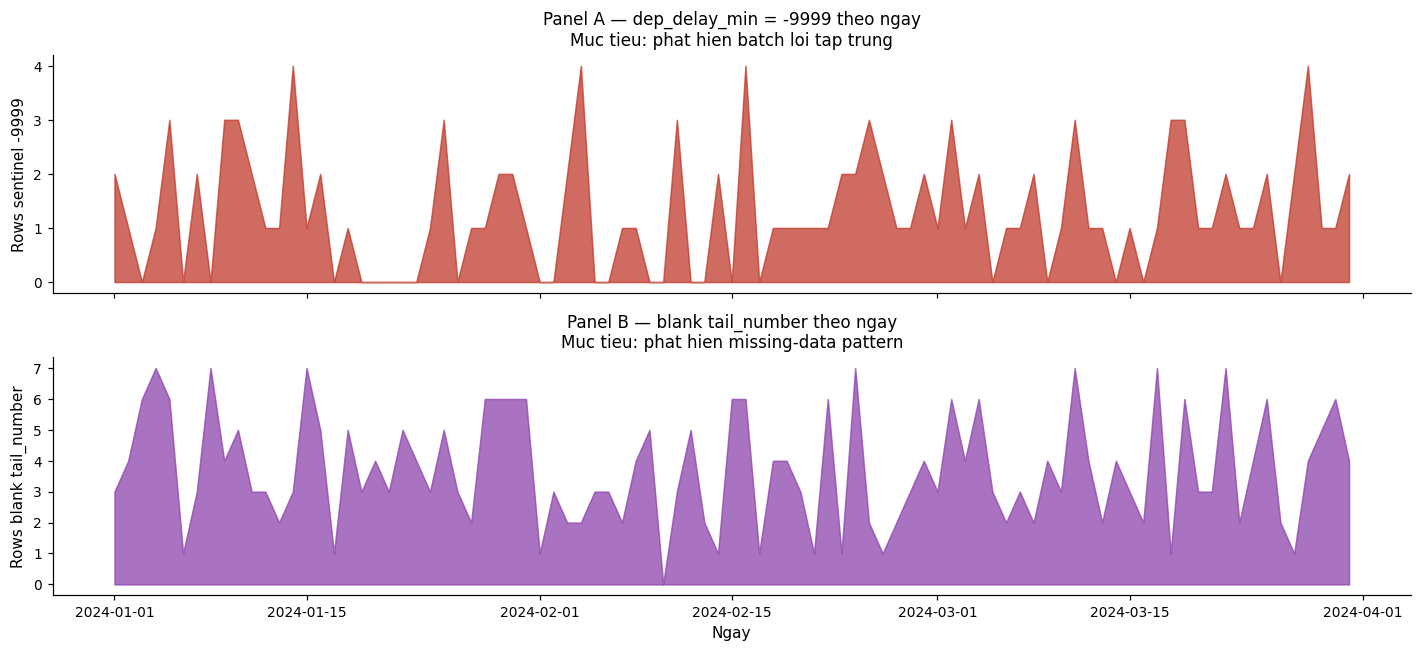

Ngay co sentinel -9999: 66 / 91 ngay
        dt  total  sentinel_9999  blank_tail
2024-01-01    672           2.00        3.00
2024-01-02    650           1.00        4.00
2024-01-04    655           1.00        7.00
2024-01-05    675           3.00        6.00
2024-01-07    664           2.00        3.00
2024-01-09    646           3.00        4.00
2024-01-10    642           3.00        5.00
2024-01-11    675           2.00        3.00
2024-01-12    668           1.00        3.00
2024-01-13    650           1.00        2.00


In [16]:
# Chart 2: Missing-data pattern theo thoi gian
missing_by_date = con.execute("""
    SELECT
        CAST(flight_date AS DATE)                                              AS dt,
        COUNT(*)                                                               AS total,
        SUM(CASE WHEN dep_delay_min = -9999                  THEN 1 ELSE 0 END) AS sentinel_9999,
        SUM(CASE WHEN TRIM(COALESCE(tail_number,'')) = ''    THEN 1 ELSE 0 END) AS blank_tail
    FROM raw_flights
    GROUP BY CAST(flight_date AS DATE)
    ORDER BY CAST(flight_date AS DATE)
""").df()
missing_by_date['dt'] = pd.to_datetime(missing_by_date['dt'])

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

axes[0].fill_between(missing_by_date['dt'], missing_by_date['sentinel_9999'],
                     alpha=0.75, color='#C0392B')
axes[0].set_ylabel('Rows sentinel -9999')
axes[0].set_title('Panel A — dep_delay_min = -9999 theo ngay\nMuc tieu: phat hien batch loi tap trung')

axes[1].fill_between(missing_by_date['dt'], missing_by_date['blank_tail'],
                     alpha=0.75, color='#8E44AD')
axes[1].set_ylabel('Rows blank tail_number')
axes[1].set_title('Panel B — blank tail_number theo ngay\nMuc tieu: phat hien missing-data pattern')
axes[1].set_xlabel('Ngay')

plt.tight_layout()
plt.savefig('output/image/chart2_missing_by_date.png', bbox_inches='tight')
plt.show()

days_with_sentinel = missing_by_date[missing_by_date['sentinel_9999'] > 0]
print(f'Ngay co sentinel -9999: {len(days_with_sentinel)} / {len(missing_by_date)} ngay')
if not days_with_sentinel.empty:
    print(days_with_sentinel[['dt','total','sentinel_9999','blank_tail']].head(10).to_string(index=False))


### 📊 Chart 3 — Cancellation pattern theo hãng bay

**Mục tiêu kiểm tra:** Tỷ lệ cancel/divert có phân phối đồng đều giữa các carrier không?  
Nếu 1 carrier có tỷ lệ cao bất thường → có thể là data coverage lệch, không nhất thiết là chất lượng vận hành.  
> ⚠️ Không kết luận hãng nào "tốt hơn" — chỉ quan sát pattern để chuẩn bị profiling Phase 2.


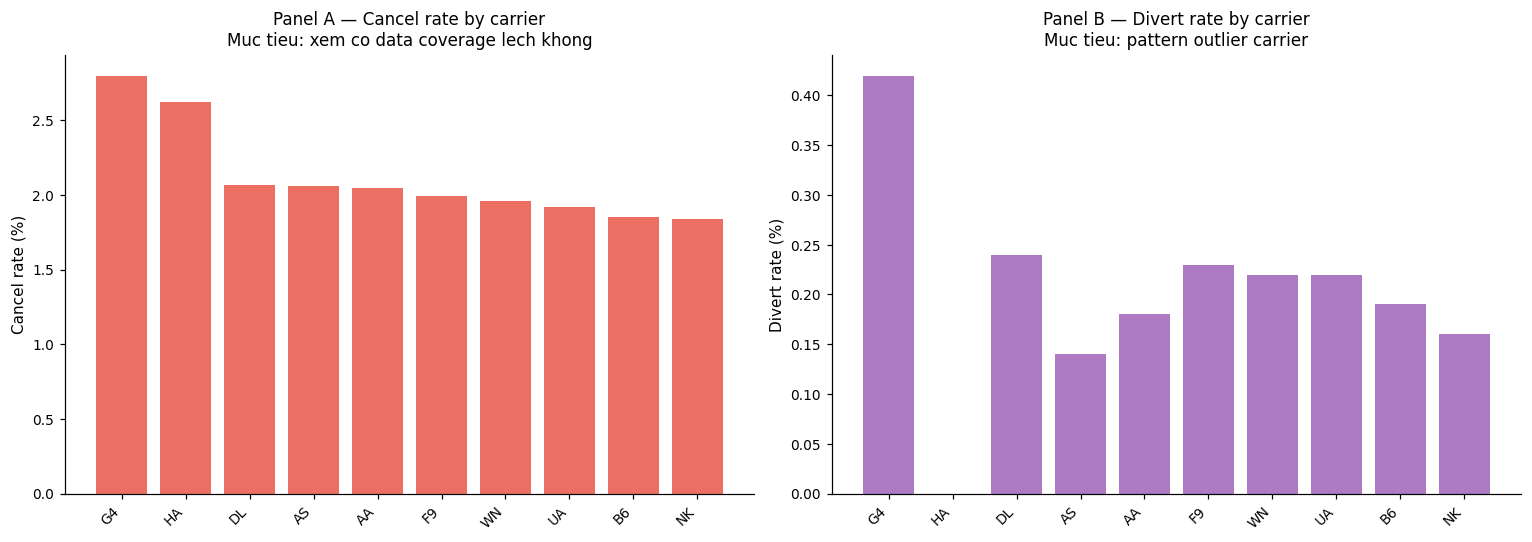

carrier_code       carrier_name  total  cancelled  cancel_pct  diverted  divert_pct
          G4      Allegiant Air   1681      47.00        2.80      7.00        0.42
          HA  Hawaiian Airlines    803      21.00        2.62      0.00        0.00
          DL    Delta Air Lines  11880     246.00        2.07     28.00        0.24
          AS    Alaska Airlines   4267      88.00        2.06      6.00        0.14
          AA  American Airlines  12198     250.00        2.05     22.00        0.18
          F9  Frontier Airlines   1710      34.00        1.99      4.00        0.23
          WN Southwest Airlines  10283     202.00        1.96     23.00        0.22
          UA    United Airlines  11120     213.00        1.92     24.00        0.22
          B6    JetBlue Airways   3679      68.00        1.85      7.00        0.19
          NK    Spirit Airlines   2559      47.00        1.84      4.00        0.16


In [17]:
# Chart 3: Cancel & divert pattern by carrier
carrier_cancel = con.execute("""
    SELECT
        f.carrier_code,
        c.carrier_name,
        COUNT(*)                                          AS total,
        SUM(f.cancelled)                                  AS cancelled,
        SUM(f.diverted)                                   AS diverted,
        ROUND(SUM(f.cancelled)*100.0/COUNT(*), 2)         AS cancel_pct,
        ROUND(SUM(f.diverted)*100.0/COUNT(*), 2)          AS divert_pct
    FROM raw_flights f
    JOIN raw_carriers c USING (carrier_code)
    GROUP BY f.carrier_code, c.carrier_name
    ORDER BY cancel_pct DESC
""").df()

x = range(len(carrier_cancel))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(x, carrier_cancel['cancel_pct'], color='#E74C3C', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(carrier_cancel['carrier_code'], rotation=45, ha='right')
axes[0].set_ylabel('Cancel rate (%)')
axes[0].set_title('Panel A — Cancel rate by carrier\nMuc tieu: xem co data coverage lech khong')

axes[1].bar(x, carrier_cancel['divert_pct'], color='#9B59B6', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(carrier_cancel['carrier_code'], rotation=45, ha='right')
axes[1].set_ylabel('Divert rate (%)')
axes[1].set_title('Panel B — Divert rate by carrier\nMuc tieu: pattern outlier carrier')

plt.tight_layout()
plt.savefig('output/image/chart3_cancel_by_carrier.png', bbox_inches='tight')
plt.show()
print(carrier_cancel[['carrier_code','carrier_name','total','cancelled','cancel_pct','diverted','divert_pct']].to_string(index=False))


### 📊 Chart 4 — Biến động tổng chuyến bay theo ngày

**Mục tiêu kiểm tra:** Phát hiện ngày có số chuyến bay bất thường thấp/cao so với trend — dấu hiệu thiếu data (missing batch).  
> ⚠️ Không kết luận nguyên nhân kinh doanh.


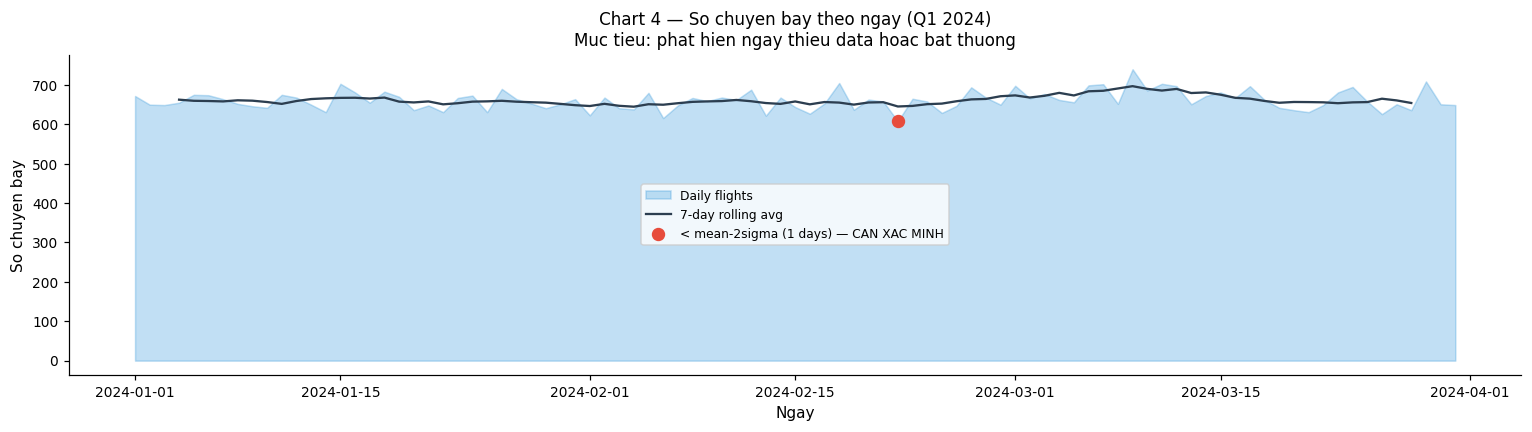

Ngay co flights < mean-2sigma (CAN XAC MINH — thieu data hay ngay le?):
        dt  total_flights  cancelled
2024-02-22            608      19.00


In [18]:
# Chart 4: Daily flight volume & anomaly detection
daily = con.execute("""
    SELECT
        CAST(flight_date AS DATE) AS dt,
        COUNT(*)                  AS total_flights,
        SUM(cancelled)            AS cancelled
    FROM raw_flights
    GROUP BY CAST(flight_date AS DATE)
    ORDER BY CAST(flight_date AS DATE)
""").df()
daily['dt'] = pd.to_datetime(daily['dt'])
daily['roll7'] = daily['total_flights'].rolling(7, center=True).mean()

mean_f = daily['total_flights'].mean()
std_f  = daily['total_flights'].std()
low_days = daily[daily['total_flights'] < mean_f - 2*std_f]

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(daily['dt'], daily['total_flights'], alpha=0.3, color='#3498DB', label='Daily flights')
ax.plot(daily['dt'], daily['roll7'], color='#2C3E50', lw=1.5, label='7-day rolling avg')
if not low_days.empty:
    ax.scatter(low_days['dt'], low_days['total_flights'],
               color='#E74C3C', zorder=5, s=60,
               label=f'< mean-2sigma ({len(low_days)} days) — CAN XAC MINH')
ax.set_title('Chart 4 — So chuyen bay theo ngay (Q1 2024)\nMuc tieu: phat hien ngay thieu data hoac bat thuong')
ax.set_ylabel('So chuyen bay')
ax.set_xlabel('Ngay')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('output/image/chart4_daily_volume.png', bbox_inches='tight')
plt.show()

if not low_days.empty:
    print('Ngay co flights < mean-2sigma (CAN XAC MINH — thieu data hay ngay le?):')
    print(low_days[['dt','total_flights','cancelled']].to_string(index=False))
else:
    print('Khong co ngay nao duoi muc mean-2sigma.')


---
## 7 · Cleaning / Normalization Plan — ĐÃ TRIỂN KHAI TRONG DBT (SQL ELT) ✅

> ✅ **Đã hoàn thành triển khai.** Kế hoạch làm sạch đã được thực thi bằng mô hình ELT hiện đại tại tầng `staging` của dbt (`stg_flights.sql`, `stg_airports.sql`).  
> Raw data (`data/raw/*.csv`) được bảo tồn 100% nguyên vẹn để phục vụ đối soát.


In [ ]:
# 7. Cleaning plan
n_dup    = con.execute("SELECT SUM(cnt-1) FROM (SELECT COUNT(*) cnt FROM raw_flights GROUP BY flight_id HAVING COUNT(*)>1)").fetchone()[0]
n_sent   = con.execute("SELECT COUNT(*) FROM raw_flights WHERE dep_delay_min = -9999").fetchone()[0]
n_orphan = con.execute("SELECT COUNT(*) FROM raw_flights WHERE dest NOT IN (SELECT airport_code FROM raw_airports)").fetchone()[0]
n_ws     = con.execute("SELECT COUNT(*) FROM raw_airports WHERE LENGTH(airport_name)!=LENGTH(TRIM(airport_name))").fetchone()[0]
n_total  = con.execute("SELECT COUNT(*) FROM raw_flights").fetchone()[0]

plan = [
    ('C-01','DQ-01',
     'Deduplicate flights',
     'ROW_NUMBER() OVER (PARTITION BY flight_id ORDER BY _loaded_at DESC) — giu rank=1',
     f'{n_dup:,} rows bi loai',
     'raw.flights giu nguyen',
     'Cho BQ-01'),
    ('C-02','DQ-02',
     'Replace sentinel -9999 -> NULL',
     'CASE WHEN dep_delay_min = -9999 THEN NULL ELSE dep_delay_min END',
     f'{n_sent:,} rows',
     'Reversible (NULL)',
     'Cho BQ-02'),
    ('C-03','DQ-03',
     'Filter orphan dest=ZZZ',
     'WHERE dest IN (SELECT airport_code FROM dim_airports)',
     f'{n_orphan:,} rows bi loai',
     'Flag is_valid_dest=false trong staging',
     'Cho BQ-03'),
    ('C-04','DQ-07',
     'TRIM airport_name',
     'TRIM(airport_name)',
     f'{n_ws:,} rows',
     'Thuan tuy string',
     'Khong can — ky thuat'),
    ('C-05','—',
     'Cast data types',
     'flight_date->DATE, dep/arr_delay->FLOAT, cancelled/diverted->BOOLEAN',
     f'{n_total:,} rows (toan bo)',
     'Type cast reversible',
     'Khong can'),
]

plan_df = pd.DataFrame(plan, columns=['Buoc','DQ-ref','Transformation','Logic','Rows affected','Rollback','Status'])
print('=== CLEANING PLAN (chua thuc thi) ===')
print(plan_df.to_string(index=False))
print('\n[REMINDER] Implement trong dbt/models/staging/stg_flights.sql & stg_airports.sql')


---
## 8 · Executive Summary & Trạng Thái Dự Án

### Data Inventory
| File | Rows | Columns | Period |
|---|---|---|---|
| flights.csv | 60,180 | 20 | Q1 2024 (91 ngày) |
| airports.csv | 40 | 8 | Reference |
| carriers.csv | 10 | 5 | Reference |
| weather.csv | 3,640 | 8 | Q1 2024 |

### Trạng Thái Phê Duyệt & Chuyển Giao
- ✅ **9 Business Questions (BQ-01 → BQ-09)**: Đã được Owner/PM phê duyệt chính thức.
- ✅ **Phương án chuẩn hóa**: Thống nhất dùng SQL/dbt theo mô hình ELT (tránh tràn RAM, minh bạch audit, tốc độ xử lý hàng triệu dòng trong vài giây).
- ✅ **Giai đoạn 2 (dbt Star Schema)**: Đã triển khai hoàn tất và kiểm thử xanh 100% (`stg_flights.sql`, `fact_flights`, `dim_airport`, `dim_airline`, `dim_date`).

### Next Steps
1. **[Giai đoạn 3]** Xây dựng Semantic Model & DAX Measures trên Power BI từ 9 tệp Parquet đã xuất khẩu.
2. **[Giai đoạn 4]** Thiết lập Apache Airflow DAGs & Great Expectations tự động hóa batch ingestion.
3. **[Giai đoạn 5]** Huấn luyện mô hình LightGBM & đóng gói FastAPI phục vụ dự báo rủi ro trễ chuyến.
